*Notebook 06 of 12 in `notebooks/scripts_text/`. Parameters: `analysis/scripts_text/config.yaml`; decisions and run notes: `analysis/scripts_text/LOG.md`. The static page `site/scripts/index.html` is built from the same outputs.*

In [1]:
import sys
from pathlib import Path

REPO = Path.cwd().resolve().parents[1]   # notebooks/scripts_text -> repo root
sys.path.insert(0, str(REPO))

import warnings

import pandas as pd
import plotly.io as pio
from IPython.display import Markdown, display

from analysis.static_figures import use_static_figures

from analysis.scripts_text import s06_null as step

use_static_figures()   # figures become static PNGs (they show on GitHub); interactive ones are on the static page
warnings.filterwarnings("ignore", category=RuntimeWarning)   # known 0/0 on very short arcs, handled downstream
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 200)
pd.set_option("display.max_colwidth", 120)

## Step 6 · Compared to what? A shuffle null

**What we do.** We keep every script and its words, but shuffle the success labels 1,000 times and redo the
Scattertext each time. The shuffle is **stratified**: labels are only swapped between films in the same genre ×
decade cell, so each shuffled world has the same genre and era mix in each group as the real one. For each
shuffle we record (i) every term's score and (ii) how many terms clear the 2× threshold.

**Why.** Step 5 always finds "distinctive" words: with thousands of words and a few hundred scripts, some will
be twice as frequent in one group by luck. The question is whether the real comparison finds *more*, or more
extreme, differences than random groupings do. This is the course's "compared to what" (weeks 2-4 null
models).

**What it measures.** For the count: z = (real − mean of shuffles) / standard deviation of shuffles, and the
empirical p = (1 + number of shuffles at least as extreme) / (1 + 1,000), which is never exactly 0. For each
term: the same against that term's own shuffle distribution, corrected for testing thousands of terms
(Benjamini-Hochberg, and a stricter family-wise test against the largest score in each shuffle).

**What it misses.** The null keeps genre and decade fixed but not budget, stars or anything else. It tests
whether the vocabularies differ, not why.

In [2]:
res = step.run()   # recomputes this step and saves its outputs

**Figure.** Grey: the number of terms at least twice as frequent in one group, in each of 1,000 stratified shuffles. Green outline: the same under unstratified shuffles. Orange line: the real comparison. If the line sits inside the grey histogram, the real groups are no more different than random groups.

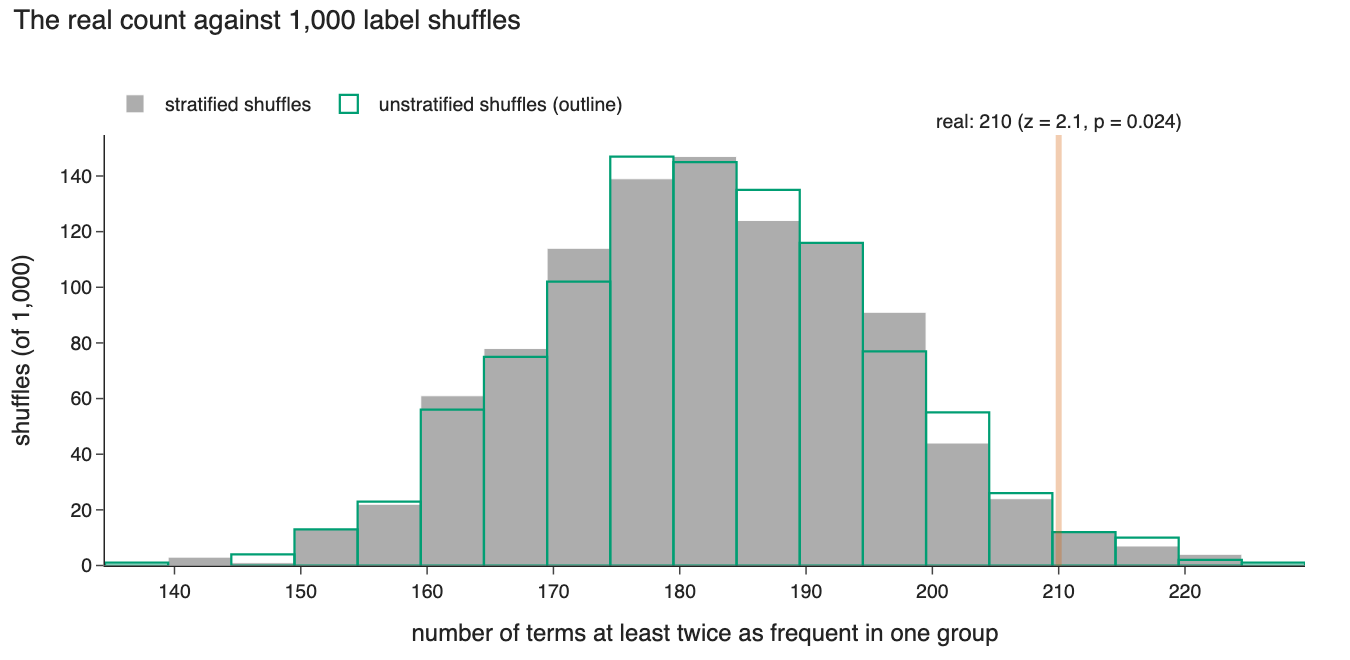

In [3]:
step.figures(res)["count_null"].show()

**Table.** The count test, overall and per side, with the unstratified shuffle for comparison.

In [4]:
display(step.tables(res)["count_tests"])

,test,real count,null mean,null std,null 5th-95th pct,z,empirical p
0,"all terms, stratified shuffle (primary)",210,182.0,13.4,161–204,2.08,0.0240
1,"successful side, stratified",124,96.7,18.3,68–125,1.50,0.0729
2,"unsuccessful side, stratified",86,85.4,18.2,61–117,0.04,0.4366
3,"all terms, unstratified shuffle (secondary)",210,182.4,13.5,160–205,2.04,0.0260


**Figure.** Every term's real score (x) against its z-score within its own shuffle distribution (y). Terms in orange survive Benjamini-Hochberg correction at q < 0.05.

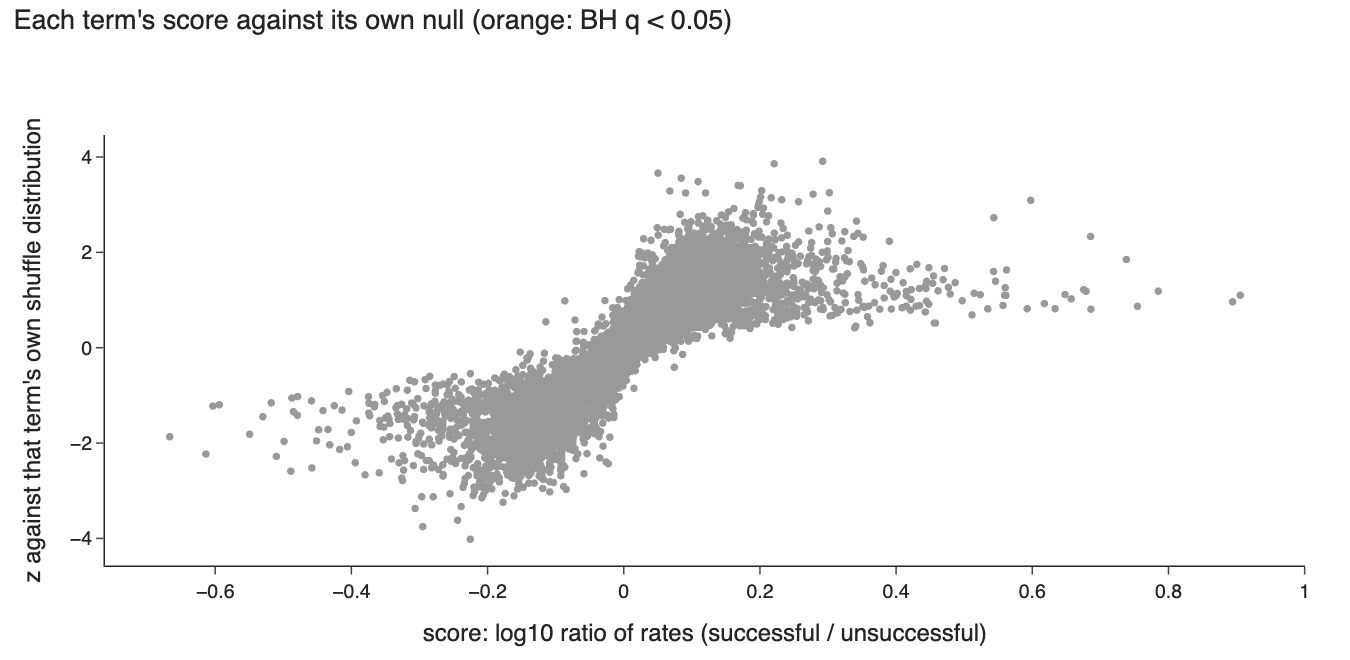

In [5]:
step.figures(res)["term_z"].show()

**Table.** The 15 most extreme terms on each side with their null statistics.

In [6]:
display(step.tables(res)["top_terms"])

,term,doc_freq,score,z,p_empirical,q_bh,p_familywise
0,je,19,0.9055,1.1004,0.0569,0.8846,0.1508
1,pas,18,0.8941,0.9630,0.1508,0.8846,0.1768
2,rocky,37,0.7851,1.1868,0.0579,0.8846,0.5884
3,c'est,14,0.7544,0.8685,0.2597,0.9105,0.7313
4,balboa,6,0.7381,1.8497,0.0020,0.6448,0.7902
5,il,17,0.6861,0.8085,0.3806,0.9623,0.9550
6,parker,22,0.6856,2.3342,0.0070,0.6660,0.9550
7,yah,34,0.6790,1.1845,0.4006,0.9623,0.9670
8,chancellor,6,0.6754,1.2166,0.1638,0.8846,0.9740
9,vous,19,0.6572,1.0237,0.1179,0.8846,0.9900


**Plain-language reading** (generated from the saved numbers):

In [7]:
display(Markdown(step.reading(res)))

In the real comparison 210 terms are at least twice as frequent in one group. Under 1,000 label shuffles within 31 genre × decade cells, that count averages 182.0 (standard deviation 13.4; 90% of shuffles between 161 and 204), so z = 2.08 and the empirical p = 0.024. The real count sits at the upper edge of the null distribution: **weak evidence** that the two groups differ in vocabulary more than random groupings within the same genre and decade cells. The excess is on the successful side (z = 1.50, p = 0.073); the unsuccessful side looks like chance (z = 0.04, p = 0.437). It is one test among several in these notebooks, and Steps 8 and 10 check what the extra terms are. Many terms clear the threshold under every shuffle: with 18,719 terms and a few hundred scripts per group, rare words cross 2× by chance. Per term, 0 pass a Benjamini-Hochberg q < 0.05 and 0 beat the null of the largest score at p < 0.05 (the smallest p possible with 1,000 shuffles is 0.0010). A single real value is not a finding; it only means something next to this histogram.